# Scaled Dot-Product Attention

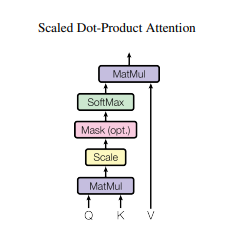

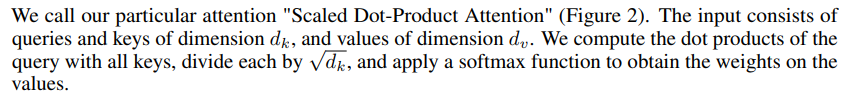

Para essa implementação a atenção maxima deve ser em relação aos shapes das matrizes:
- Q, K, V shapes: [L, dim]
- Q @ K.T : [Lq, Lk]
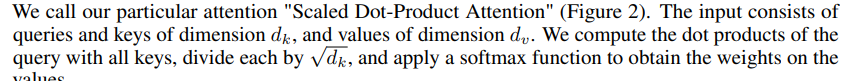

In [15]:
from pathlib import Path
import sys

path = Path('..').resolve()

if path not in sys.path:
    sys.path.append(str(path))

In [ ]:
import math
import torch
from src.functional import softmax

In [ ]:
def scaled_dot_product_attention(
    q: torch.Tensor,
    v: torch.Tensor,
    k: torch.Tensor,
    attn_mask=None,
) -> torch.Tensor:

    d_k = k.size(-1) # [B, H, Lk, dk]
    
    attn_scores = (
        torch.matmul(
            q,
            k.transpose(-2, -1) 
        ) / math.sqrt(d_k)
    ) # [B, H, Lq, Lk]

    if attn_mask is not None:
        attn_scores = attn_scores.masked_fill(
            attn_mask == 0,
            float('-inf')
        )

    prob_attn = softmax(
        attn_scores,
        dim=-1
    )

    attn_output = torch.matmul(
        prob_attn, v
    )

    return attn_output, prob_attn 

In [18]:
B = 2
H = 4
Lq = 3
Lk = 5
dk = 8
dv = 8

q = torch.randn(B, H, Lq, dk)
k = torch.randn(B, H, Lk, dk)
v = torch.randn(B, H, Lk, dv)

output, prob_attn = scaled_dot_product_attention(q, k, v)

print("output:", output.shape)
print("prob_attn:", prob_attn.shape)

output: torch.Size([2, 4, 3, 8])
prob_attn: torch.Size([2, 4, 3, 5])


- OUTPUTS: Para cada query, produzir um novo vetor combinando values, atribuindo mais peso aos values associados as keys mais relevantes.
    - attn_output: São novas representações dos tokens dado o contexto.
    - prob_attn: diz o quanto cada QUERY deve dar atenção para cade KEY.
    